In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statistics import mode


pd.set_option('display.max_columns', None)

# Read the text file into a DataFrame
df= pd.read_csv(r'data.csv')

In [2]:
df.shape

(2443651, 9)

In [3]:
df.sample(5)

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
1702545,1916539,B0CDWT9V4G,"Freeze Fat Removal Instrument, Fat Freezing Ma...",0.0,0,278.25,False,0,Sports Supplements
1782792,2006787,B0BJPXZ7BY,"Vycowb 100PCS Pad, Electrode Replacement Pad, ...",0.0,0,11.31,False,0,Sports & Outdoors
1708534,1924376,B07YCMV6XV,"Kids 510 Skinny Fit Jean Class Boys, 10-16 Yea...",4.4,863,34.99,False,0,Customers' Most Loved
398816,425509,B083QY21W6,DEMIL 6PCS/8PCS/12PCS Seamless Headband Bandan...,4.4,1669,15.61,False,0,Sports & Outdoors
885152,962854,B0CJNFQXD8,"TURHAN Skipping Rope, Fitness Speed Jump Rope ...",0.0,0,32.36,False,0,Sports & Outdoors


## Part 1: Understanding Product Categories
### 1. Frequency Tables:

In [4]:
## Generate a frequency table for the product category.
category_counts = df['category'].value_counts()
category_counts.columns = ['Category', 'Frequency']


# Calculate the proportion of each unique value in the 'category'
proportion_table = df['category'].value_counts(normalize=True)
category_counts.head(5), proportion_table.head(5)
proportion_table.columns = ['Category', 'Frequency']
category_counts.head(5), proportion_table.head(5)

(category
 Sports & Outdoors                         836265
 Beauty                                     19312
 Handmade Clothing, Shoes & Accessories     19229
 Bath & Body                                19092
 Birthday Gifts                             18978
 Name: count, dtype: int64,
 category
 Sports & Outdoors                         0.342219
 Beauty                                    0.007903
 Handmade Clothing, Shoes & Accessories    0.007869
 Bath & Body                               0.007813
 Birthday Gifts                            0.007766
 Name: proportion, dtype: float64)

In [5]:
# Displaying the top 5 categories
top_5_categories = category_counts.head(5)
top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

### 2. Visualizations:

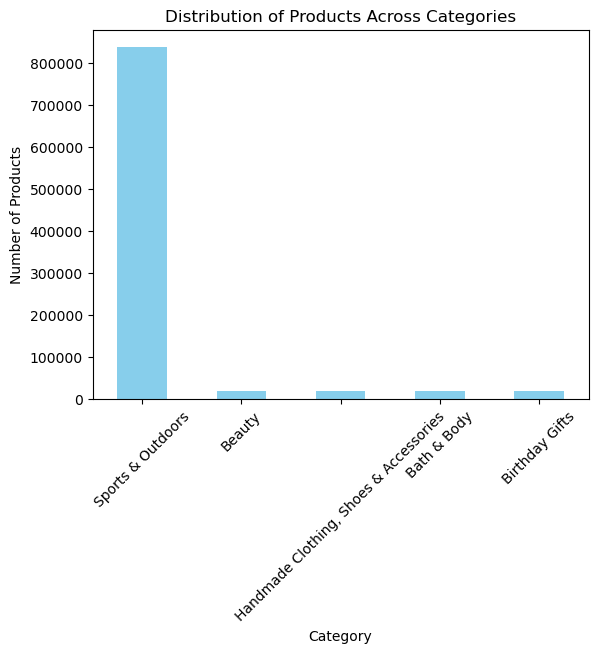

In [6]:
##Display the distribution of products across different categories using a bar chart. 
top_5_categories.plot(kind='bar', color='skyblue')
plt.title('Distribution of Products Across Categories')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=45)
plt.show()

**Insights**:

- 'Sports & Outdoors' category dominates over other categories.


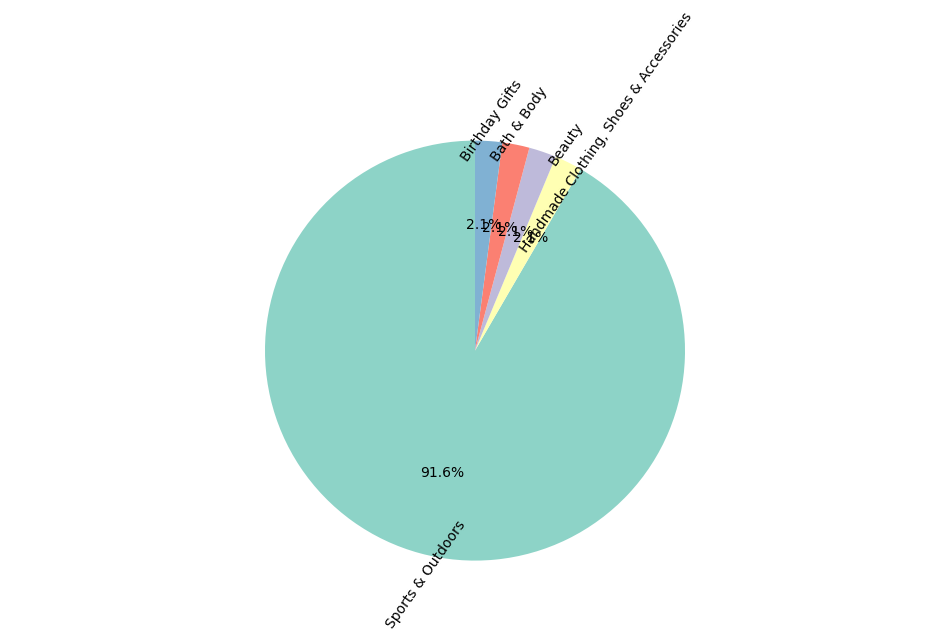

In [61]:
 
# Plotting the pie chart
fig, ax = plt.subplots(figsize=(12, 6))
wedges, texts, autotexts = ax.pie(top_5_categories, labels=top_5_categories.index, autopct='%1.1f%%', startangle=90, colors=sns.color_palette("Set3"))

# Adjusting text position, alignment, and rotation
for text in texts:
    text.set_horizontalalignment('left')  # Shift text to the left
    x, y = text.get_position()
    text.set_position((x - 0.15, y))  # Adjust the position slightly to the left
    text.set_rotation(55)  # Rotate text by 30 degrees (adjust as needed)

plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

### Insights: 'Sports & Outdoors' category is most dominating category among top 5 categories with share of 91.6%


## Part 2: Delving into Product Pricing

### 1. **Measures of Centrality**:

- Calculate the mean, median, and mode for the `price` of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [8]:
#calculaitn mean, mean standard deviation, minimum, maximum, 25th percentile, 50th percentile, 75th percentile 
# using describe function
df.describe()


,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [9]:
#calculating the mode of the price
mode_price = df['price'].mode()[0]
mode_price

9.99

**Insights** from Summary Statistics for 'price':

- The average (mean) price for Amazon UK products in the dataset is approximately £89.24.

- The median sale price (middle value when sorted) is £19.09. This value is significantly lower than the mean, indicating that the distribution of sale prices is skewed towards higher values.

- The mode price (the most common price) is £9.99.

### 2. **Measures of Dispersion**:

- Determine the variance, standard deviation, range, and interquartile range for product `price`.
- How varied are the product prices? Are there any indicators of a significant spread in prices?

In [10]:
#calculating the variance, standard deviation, range, and interquartile range of the price
variance = df['price'].var()
std_dev = df['price'].std()
range = df['price'].max() - df['price'].min()
iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)
print('Variance:', variance, '\n''Standard Deviation:', std_dev,  '\n''price_range:', range, '\n''Interquartile Range (IQR):', iqr)

Variance: 119445.48532256528 
Standard Deviation: 345.60886175352226 
price_range: 100000.0 
Interquartile Range (IQR): 36.0


**Insights** :

- The standard deviation, which measures the amount of variation or dispersion in the sale prices, is approximately £345.60. This indicates that sale prices can vary significantly from the average.
- The minimum and maximum sale prices are £0 and £100,000, respectively, highlighting a wide range of product values in the dataset.
- The interquartile range (IQR), represented by the values at the 25th percentile (Q1) and the 75th percentile (Q3), spans from £9.99 to £45.99. This means that 50% of the items in the Amazon UK dataset were sold within this price range.


### 3. **Visualizations**:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

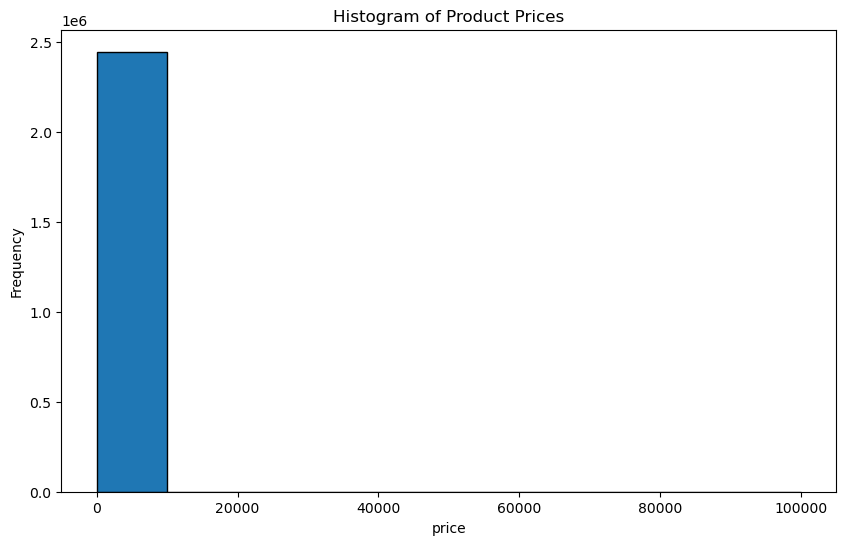

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(df['price'], bins=10, edgecolor='black')
plt.xlabel('price')
plt.ylabel('Frequency')
plt.title('Histogram of Product Prices')
plt.show()

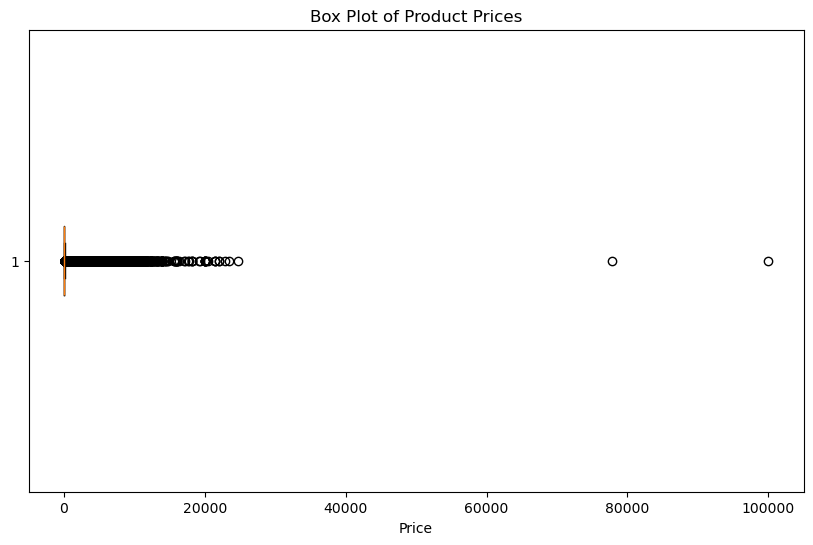

In [71]:
plt.figure(figsize=(10, 6))
plt.boxplot(df['price'], vert=False)
plt.xlabel('Price')
plt.title('Box Plot of Product Prices')
plt.show()

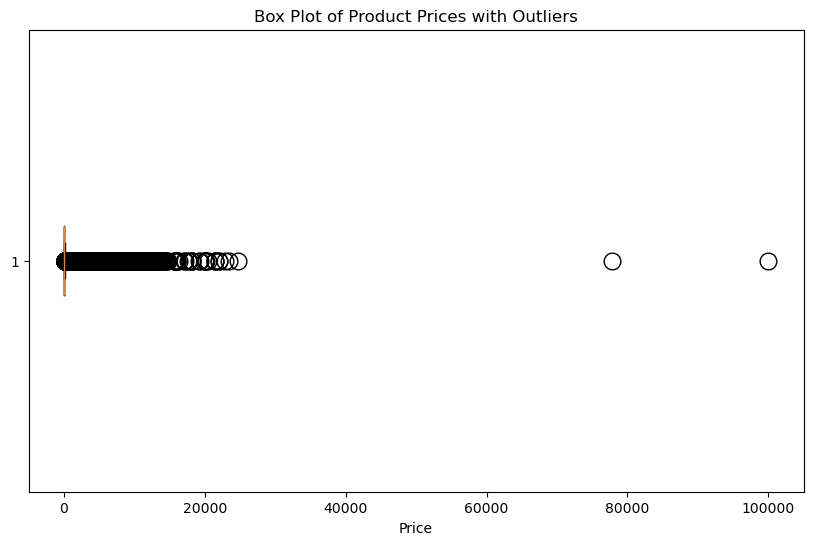

In [14]:
plt.figure(figsize=(10, 6))
plt.boxplot(df['price'], vert=False, flierprops=dict(marker='o', color='red', markersize=12))
plt.xlabel('Price')
plt.title('Box Plot of Product Prices with Outliers')
plt.show()

**Insights** from Visualizations:

- The price distribution is heavily concentrated for items valued between £0 and £10,000. As a result, the histogram does not effectively reflect the distribution for products priced outside this range.

### Filtering the max outliers

In [74]:
# Finding outliers: Define whiskers

Q1_price = df['price'].describe().loc['25%']
print(f"The Q1 (25%) for 'price' is £{Q1_price}")

Q3_price = df['price'].describe().loc['75%']
print(f"The Q3 (75%) for 'price' is £{Q3_price}")

# IQR = Q3 - Q1
IQR_price = Q3_price - Q1_price
print(f"The IQR for 'price' is £{IQR_price}")

# Q1 - (1.5 * IQR)
min_outlier_price = Q1_price - (1.5 * IQR_price)
# Q3 + 1.5 * IQR
max_outlier_price = Q3_price + (1.5 * IQR_price)
print(f"The standard prices are from £{min_outlier_price} and {max_outlier_price}")

The Q1 (25%) for 'price' is £9.99
The Q3 (75%) for 'price' is £45.99
The IQR for 'price' is £36.0
The standard prices are from £-44.01 and 99.99000000000001


### Taking out the outliers from the plot and to visualising the price distribuition


In [76]:
price_corrected = df[df['price'] < max_outlier_price]['price']
price_corrected

0          21.99
1          23.99
2          21.99
3          31.99
4          17.99
           ...  
2443646    22.34
2443647    97.99
2443648    52.99
2443649    79.99
2443650    53.99
Name: price, Length: 2115963, dtype: float64

c:\Users\reetu\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


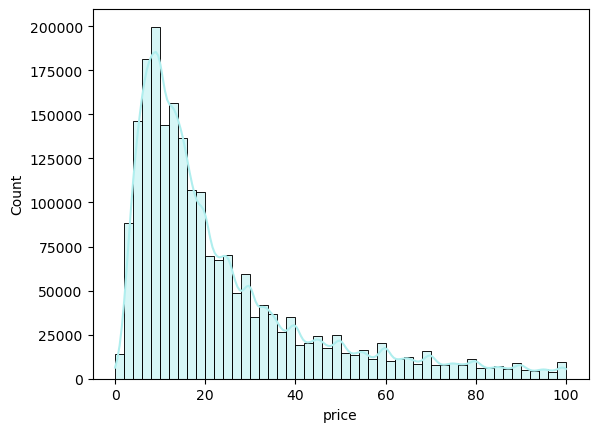

In [84]:
# Create a histogram of price values from the Amazon dataset
sns.histplot(x=price_corrected, bins=50, kde=True, color='paleturquoise');

<Axes: >

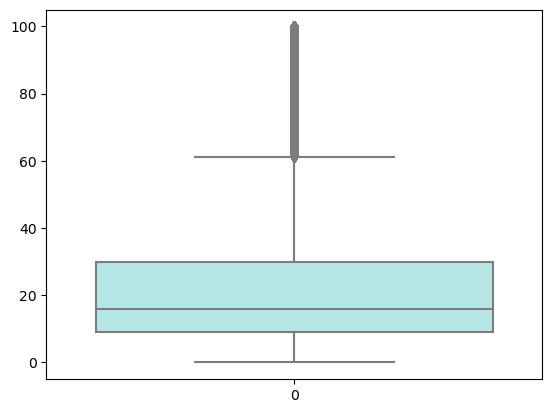

In [85]:
# Plotting a boxplot for the 'standard_prices' with a light blue color
sns.boxplot(data =price_corrected, color="paleturquoise")

**Insights**:

- After filtering out the maximum prices (which are much larger than most values in the dataset), the histogram reveals that the majority of items are sold in the price range of approximately £2 to £20. However, there is a long tail on the right side, confirming our earlier inference from the skewness value that there are items sold at much higher prices. The Kernel Density Estimate (the smooth line) also shows the right-skewed nature of the distribution.

- The box plot provides a visual representation of the central 50% of the data (the interquartile range), with the median price shown as a line inside the box. The whiskers extend to 1.5 times the interquartile range, and points outside this range are considered outliers. There are several outlier points on the higher end of the sale prices, which aligns with our earlier insights about items sold at significantly higher prices.

Both visualizations underscore the presence of outliers in the higher price range. These outliers might be luxury items or tech devices, and special attention might be needed when building predictive models, as these outliers can significantly influence model performance.

## Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

### 1. **Measures of Centrality**:

- Calculate the mean, median, and mode for the `rating` of products.
- How do customers generally rate products? Is there a common trend?

In [88]:
# Summary Statistics 
df.describe()
print('Mean:', df['price'].mean(), '\n'"median:", df['price'].median())

Mean: 89.24380943923663 
median: 19.09


In [87]:
# Finding mode  
mode(df['stars'].mode())

0.0

In [91]:
# Calculating individual statistical measures for `stars`
print(f"Individual Statistical Measure for 'stars':")
print(f" Average star rating is {df['stars'].mean()}")
print(f" Middle star rating is {df['stars'].median()}")
print(f"  star rating that appears the most is {df['stars'].mode()}")

Individual Statistical Measure for 'stars':
 Average star rating is 2.152836472966065
 Middle star rating is 0.0
  star rating that appears the most is 0    0.0
Name: stars, dtype: float64


**Insights** from Summary Statistics for 'stars':

- The average (mean) rating for Amazon UK products in the dataset is approximately 2.15. This value is influenced by both high and low ratings, including the zeros.

- The median rating (the middle value when sorted) is 0. This suggests that there are many zero ratings, which could indicate an issue with the data or reflect the actual distribution of ratings.

- The mode (the most frequently occurring value) is 0.

- Customers generally rate products on Amazon UK with 0 stars. There appears to be a pattern of rating products either 0 stars or close to 2 stars, with a strong tendency towards negative scores.

### 2. **Measures of Dispersion**:

- Determine the variance, standard deviation, and interquartile range for product `rating`.
- Are the ratings consistent, or is there a wide variation in customer feedback?

In [92]:
# Summary statistics 
df.describe().loc[['std', '25%', '75%', 'min', 'max']]

,uid,stars,reviews,price,boughtInLastMonth
std,8.160562e+05,2.194865,5.944124e+03,345.608862,240.483727
25%,6.589215e+05,0.000000,0.000000e+00,9.990000,0.000000
75%,2.060686e+06,4.400000,5.900000e+01,45.990000,0.000000
min,1.000000e+00,0.000000,0.000000e+00,0.000000,0.000000
max,2.828593e+06,5.000000,1.356658e+06,100000.000000,50000.000000


**Insights** from Summary Statistics for 'stars':

- The standard deviation, a measure of the variation or dispersion in the star ratings, is approximately 2.19. This indicates that the ratings vary moderately from the average.

- The minimum and maximum star ratings are 0 and 5, respectively, highlighting a wide range of rating values in the dataset.

- The interquartile range (IQR), represented by the values at the 25th percentile (Q1) and the 75th percentile (Q3), spans from 0 to 4.40. This means that 50% of the items in the Amazon UK dataset were rated within this range.

- The ratings are not fully consistent, as there is a wide variation in customer feedback, ranging from the lowest to the highest ratings.

### 3. **Shape of the Distribution**:

- Calculate the skewness and kurtosis for the `rating` column. 
- Are the ratings normally distributed, or do they lean towards higher or lower values?

In [94]:
#calculating the skewness and kurtosis of the star ratings
skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

print("Skewness:", skewness_rating, "Kurtosis:", kurtosis_rating)

Skewness: 0.08120735761080985 Kurtosis: -1.9260061280432985


- Skewness of 'stars': \(0.08\)
- Kurtosis of 'stars': \(-1.92\)

**Insights** from Shape of the Distribution:

1. **Skewness**: Skewness: The near-zero skewness (0.08) for the 'stars' indicates that the distribution is approximately symmetric. This suggests that the tail on the right side (higher ratings) is slightly longer than the tail on the left side (lower ratings). In practical terms, this implies that there are some products with higher star ratings acting as outliers, pulling the mean slightly upwards.
  
2. **Kurtosis**: The kurtosis value of -1.92 indicates that the 'stars' rating distribution has light tails and a flatter peak compared to a normal distribution. This means there are fewer extreme values (outliers) in the 'stars' ratings than one would expect in a normally distributed dataset.

The skewness and kurtosis values suggest that the distribution of star ratings is relatively symmetric but with fewer extreme high or low ratings compared to a normal distribution.

### 4. **Visualizations**:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

c:\Users\reetu\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


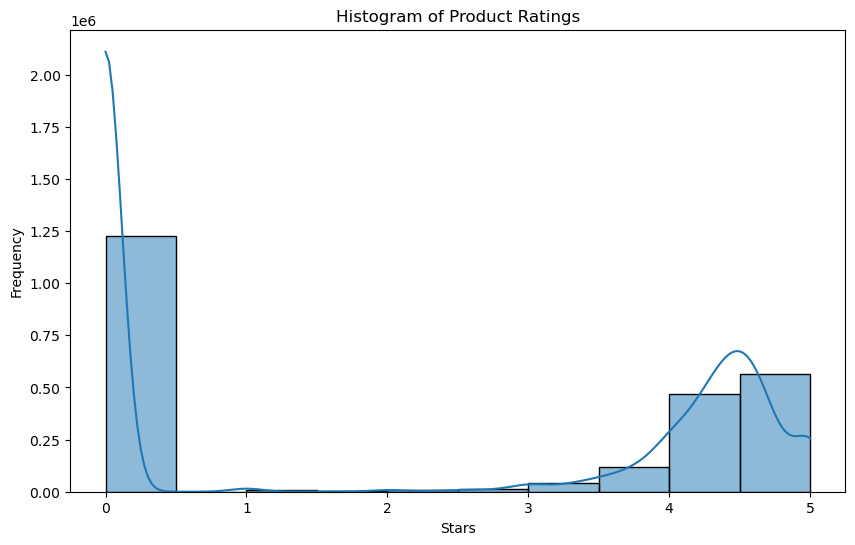

In [95]:
# Histogram
plt.figure(figsize=(10, 6))
sns.histplot(df['stars'], bins=10, kde=True)
plt.xlabel('Stars')
plt.ylabel('Frequency')
plt.title('Histogram of Product Ratings')
plt.show()

**Insights** :

- The histogram indicates that the majority of the ratings are 0, suggesting that either customers are discontent with their purchases or they do not rate the items they buy.

- The next most frequent ratings are the top stars, primarily 4 and 4.5. This indicates a high level of customer satisfaction, suggesting that many buyers are genuinely happy with their purchases. Alternatively, it could imply that customers might feel compelled to leave positive ratings to receive a discount or reimbursement.

<module 'matplotlib.pyplot' from 'c:\\Users\\reetu\\anaconda3\\Lib\\site-packages\\matplotlib\\pyplot.py'>

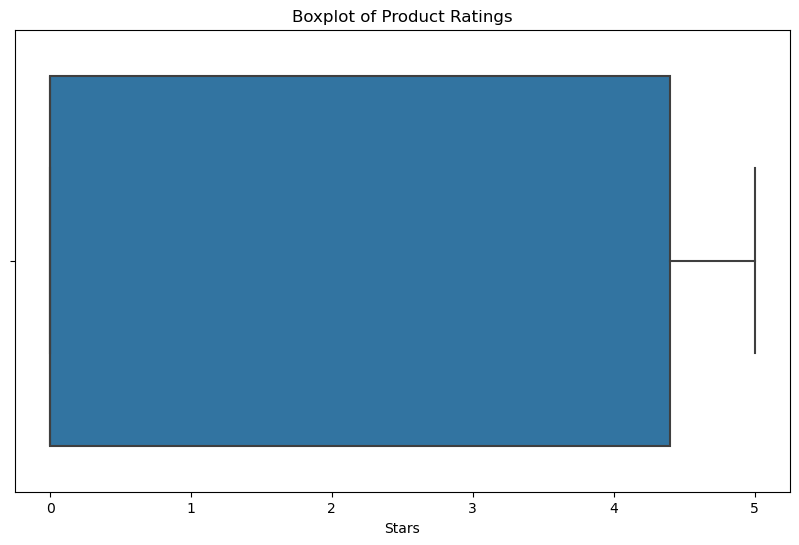

In [99]:
# Boxplot
plt.figure(figsize=(10, 6))
sns.boxplot(x = df['stars'])
plt.xlabel('Stars')
plt.title('Boxplot of Product Ratings')
plt